### Build A Basic Chatbot With Langgraph(GRAPH API)

In [12]:
from typing import Annotated,TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [13]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [14]:
# state_goh = StateGraph(State)
# print(state_goh)

In [15]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [16]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="llama3-8b-8192")

In [17]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'Llama 3 8B', 'status': 'deprecated', 'release_date': '2024-04-18', 'last_updated': '2024-04-18', 'open_weights': True, 'max_input_tokens': 8192, 'max_output_tokens': 8192, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000295A95A9A90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000295A95AA490>, model_name='llama3-8b-8192', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [18]:
llm = init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000295A95AAE90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000295A95AB890>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [19]:
# Node functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}


In [20]:
graph_builder = StateGraph(State)
### Adding node
graph_builder.add_node("llmchatbot",chatbot)

## Add Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

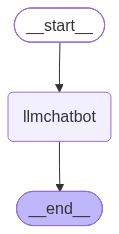

In [21]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [22]:
response=graph.invoke({"messages":"Hi"})

In [23]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [24]:
for event in graph.stream({"messages":"Hi how are you"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I'm doing great—thanks for asking. How are you doing today? Anything interesting on your end?


In [25]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("Latest news Cockroach party")

{'query': 'Latest news Cockroach party',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.nytimes.com/live/2026/10/09/world/india-cjp-cockroach-protest',
   'title': 'Live Updates: Protesters Converge on New Delhi Over Cuts to India’s Voter Roll - The New York Times',
   'content': 'Now, the Gen Z movement that Abhijeet Dipke birthed five months ago and called the Cockroach Janta Party has become a formidable finger in the eye of the Indian government.\n\nThe cockroaches’ latest aim is the resignation of the country’s chief election commissioner, over what they say is a politically motivated purge of 130 million voters from the election rolls.',
   'score': 0.78866494,
   'raw_content': None,
   'id': '6778ec-00'},
  {'url': 'https://www.bbc.com/news/live/cwg7xz8vr58pt',
   'title': "CJP protests at Delhi's Jantar Mantar: India 'cockroach' party says Abhijit Dipke and Saurabh Das detained ahead of march - BBC News",
   'content': "Now, the

In [26]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [27]:
tools = [tool,multiply]

In [28]:
llm_with_tool = llm.bind_tools(tools)

In [29]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000295A95AAE90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000295A95AB890>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

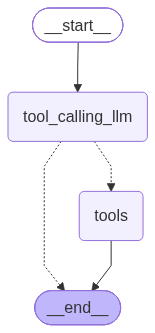

In [30]:
# Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode, tools_condition
## Node Defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [42]:
response = graph.invoke({"messages":"whhat is latest ai news"})
print(response)


{'messages': [HumanMessage(content='whhat is latest ai news', additional_kwargs={}, response_metadata={}, id='a6883139-2db0-4181-98ff-fd54065a4246'), AIMessage(content='', additional_kwargs={'reasoning_content': 'User typed "whhat is latest ai news". They want the latest AI news. We should provide up-to-date information. We can use the search tool to get current news. Let\'s search.', 'tool_calls': [{'id': 'fc_0716a768-7b01-4315-b049-f53e525873f9', 'function': {'arguments': '{"query":"latest AI news 2026-10-10","search_depth":"basic","time_range":"day","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 88, 'prompt_tokens': 348, 'total_tokens': 436, 'completion_time': 0.097081621, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.025900647, 'prompt_tokens_details': None, 'queue_time': 0.337184597, 'total_time': 0.122982268}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_feb9b278

In [36]:
response['messages'][-1].content

'Hello! How can I help you today?'

In [39]:
import json
from langchain_core.messages import ToolMessage

tool_message = next(
    msg for msg in reversed(response["messages"])
    if isinstance(msg, ToolMessage)
)

data = json.loads(tool_message.content)

for article in data["results"]:
    print("Title:", article["title"])
    print("Content:", article["content"])
    print("URL:", article["url"])
    print("Published:", article.get("published_date"))
    print("-" * 80)

Title: AI News October 10, 2026: 6 Stories Explained | explainx.ai
Content: FBI agents arrested Cypfer co-founder Edward Dubrovsky in Pennsylvania on October 8, 2026, in the ShinyHunters probe; charges are extortion-related and the complaint is sealed.

## Key questions from October 10, 2026

What was the biggest AI news on October 10, 2026?
:   The top AI stories explainx.ai reported on October 10, 2026 were White House AI Incident Disclosure Mandate: What It Says; Underdog Saluki 27B: 54 GB Model in 7.89 GB (GGUF); and InnovationEval: AI Agents Fail to Reinvent SDPO (2026). The White House says AI companies must immediately disclose incidents involving their models and remedy harm, but has not said how it will be enforced or what penalties apply. [...] Google confirms Colab perks in Google AI plans (priority access for all paid tiers, Premium GPUs and background runs for Ultra), but it names no A100 or H100 and no 200-unit allotment for Pro.
4. 05Chips, compute & infrastructure

   #

In [41]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
print(response)
for m in response['messages']:
    m.pretty_print()

{'messages': [HumanMessage(content='What is 5 multiplied by 2', additional_kwargs={}, response_metadata={}, id='a1461759-9069-4174-8213-b3d0ca82d40f'), AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is 5 multiplied by 2". We should use the multiply function.', 'tool_calls': [{'id': 'fc_4dd6697d-c140-4102-93a4-21b6ba708330', 'function': {'arguments': '{"a":5,"b":2}', 'name': 'multiply'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 350, 'total_tokens': 398, 'completion_time': 0.051423052, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.252391201, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.305620182, 'total_time': 0.303814253}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_37c9245f64', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a125e3-0832-7592-9ec1-60adcbb13306

In [43]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ede3f8c3-6980-4ced-bfbe-774006ad1efe)
 Call ID: fc_ede3f8c3-6980-4ced-bfbe-774006ad1efe
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.marketingprofs.com/opinions/2026/56118/ai-update-october-09-2026-ai-news-and-views-from-the-past-week", "title": "Artificial Intelligence - AI Update, October 09, 2026: AI News and Views From the Past Week", "content": "Mistral unveils Large 4, claiming gains against Chinese open-weight AI rivals. French AI startup Mi

### ReAct Agent Architecture

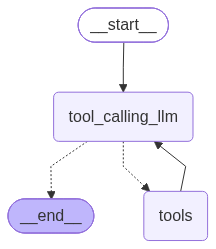

In [44]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [45]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3ef4225e-ac69-40d2-9d9e-0c710dcadf00)
 Call ID: fc_3ef4225e-ac69-40d2-9d9e-0c710dcadf00
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.marketingprofs.com/opinions/2026/56118/ai-update-october-09-2026-ai-news-and-views-from-the-past-week", "title": "Artificial Intelligence - AI Update, October 09, 2026: AI News and Views From the Past Week", "content": "Mistral unveils Large 4, claiming gains against Chinese open-weight AI rivals. French AI startup Mistr

## Adding Memory In Agentic Graph

In [46]:
response=graph.invoke({"messages":"Hello my name is Narsimha"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Narsimha
================================== Ai Message ==================================

Hello Narsimha! How can I assist you today?


In [47]:
response=graph.invoke({"messages":"What is my Name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my Name
================================== Ai Message ==================================

I’m sorry, but I don’t have any information about your name. If you’d like me to address you by a particular name, just let me know!


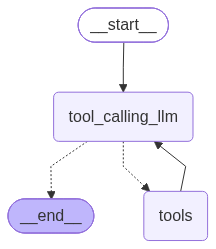

In [52]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [53]:
# using the thread for a particular session to remeber the conversation memory
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Narsimha"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Narsimha', additional_kwargs={}, response_metadata={}, id='8ff3a013-45e7-443e-8f3a-75783233e525'),
  AIMessage(content='Hello Narsimha! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi my name is Narsimha". Likely want a friendly reply. No action needed.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 349, 'total_tokens': 397, 'completion_time': 0.061706343, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.076191124, 'prompt_tokens_details': None, 'queue_time': 0.220306465, 'total_time': 0.137897467}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a12402de73', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a125ff-f23d-7172-9b60-38c8d236f692-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 349, 'output_tokens': 48, 'total_tokens': 397,

In [54]:
response["messages"][-1].content

'Hello Narsimha! 👋 How can I help you today?'

In [55]:
response=graph.invoke({"messages":"What is my Name ?"},config=config)
print(response["messages"][-1].content)

Your name is **Narsimha**.


In [56]:
response=graph.invoke({"messages":"Hey do you remember me?"},config=config)
print(response["messages"][-1].content)

I do! You’re Narsimha. How can I help you today?


## Streaming

In [57]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [58]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

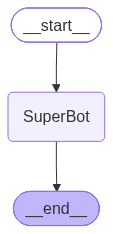

In [59]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [60]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Narsimha And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Narsimha And I like cricket', additional_kwargs={}, response_metadata={}, id='787ee42f-aae6-48c9-9062-fdaf170bacc8'),
  AIMessage(content='Hey Narsimha! 👋 Cricket’s a fantastic sport. Do you have a favorite team or player? Or maybe you’re into any particular format—Test, ODI, or T20? Let me know what you’re most excited about!', additional_kwargs={'reasoning_content': "We need to respond in a friendly tone, maybe ask about cricket. There's no special instruction. Just a simple chat."}, response_metadata={'token_usage': {'completion_tokens': 83, 'prompt_tokens': 83, 'total_tokens': 166, 'completion_time': 0.103250333, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.004275354, 'prompt_tokens_details': None, 'queue_time': 0.211791953, 'total_time': 0.107525687}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_pr

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [61]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Narsimha And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hello Narsimha! 👋 It’s great to meet a cricket fan.  \nWhich team or player do you follow most? Or maybe you have a favorite match or moment that still gets you excited? Feel free to share—I'm all ears!", additional_kwargs={'reasoning_content': 'User says "Hi, My name is Narsimha And I like cricket". We should respond politely, maybe ask about cricket. The user didn\'t ask a question. We can greet, ask about cricket, maybe ask about favorite team, etc.'}, response_metadata={'token_usage': {'completion_tokens': 109, 'prompt_tokens': 83, 'total_tokens': 192, 'completion_time': 0.111723569, 'completion_tokens_details': {'reasoning_tokens': 50}, 'prompt_time': 0.003955645, 'prompt_tokens_details': None, 'queue_time': 0.210429544, 'total_time': 0.115679214}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1

In [62]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Narsimha And I like cricket', additional_kwargs={}, response_metadata={}, id='d708ee8b-d37c-49ca-9bcc-a3c140df7477'), AIMessage(content="Hello Narsimha! 👋 It’s great to meet a cricket fan.  \nWhich team or player do you follow most? Or maybe you have a favorite match or moment that still gets you excited? Feel free to share—I'm all ears!", additional_kwargs={'reasoning_content': 'User says "Hi, My name is Narsimha And I like cricket". We should respond politely, maybe ask about cricket. The user didn\'t ask a question. We can greet, ask about cricket, maybe ask about favorite team, etc.'}, response_metadata={'token_usage': {'completion_tokens': 109, 'prompt_tokens': 83, 'total_tokens': 192, 'completion_time': 0.111723569, 'completion_tokens_details': {'reasoning_tokens': 50}, 'prompt_time': 0.003955645, 'prompt_tokens_details': None, 'queue_time': 0.210429544, 'total_time': 0.115679214}, 'model_name': 'openai/gpt-oss-20b', 'system_finge

In [63]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! 👋 It’s great to meet a cricket fan. Do you have a favorite team or player? Or maybe you’re into any particular format—Test, ODI, T20? Let me know, and we can chat more about the game!', additional_kwargs={'reasoning_content': 'User: "Hi,My name is Krish And I like cricket". They greet. We should respond appropriately. No policy issues. Just friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 82, 'total_tokens': 176, 'completion_time': 0.10037315, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.003978733, 'prompt_tokens_details': None, 'queue_time': 0.309935282, 'total_time': 0.104351883}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12624-0ef8-73c0-add1-3dec63da69ef-0', tool_calls=[], invalid_tool_calls=[], usage_met

In [64]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='1973c820-8423-4048-9e09-57ba63eca431'), AIMessage(content='Hello Krish! 👋 It’s great to meet a cricket fan. Do you have a favorite team or player? Or maybe you’re into any particular format—Test, ODI, T20? Let me know, and we can chat more about the game!', additional_kwargs={'reasoning_content': 'User: "Hi,My name is Krish And I like cricket". They greet. We should respond appropriately. No policy issues. Just friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 82, 'total_tokens': 176, 'completion_time': 0.10037315, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.003978733, 'prompt_tokens_details': None, 'queue_time': 0.309935282, 'total_time': 0.104351883}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logpro

In [65]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a12624-7b1b-7763-bb40-8c3fe8f70b6b', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='bda4cf05-0408-44a7-81af-0e760b6f1165')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a12624-7b48-7e80-b95b-029599c193e0', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:319927a2-05b2-2fa7-d211-8b512eb940b2'}, 'parent_ids': ['01a12624-7b1b-7763-bb40-8c3fe8f70b6b']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':